# Farmacias en Ensenada: proximidad y localización
**María Guadalupe Villanueva Utrilla**

 *Proyecto de Introducción a la Ciencia de Datos*

*Pregunta principal:* ¿dónde conviene proponer cinco farmacias para beneficiar a más población en manzanas que actualmente quedan a más de 500 m de una farmacia?

*Preguntas complementarias:* ¿cómo cambia la cobertura con 1-10 propuestas?, ¿qué concentraciones de población permanecen desatendidas?, ¿qué concentraciones permanecen fuera después de cinco propuestas?

El visor conserva puntos de cuatro categorías (farmacias, escuelas, supermercados y hospitales) y concentra el modelado en farmacias. La salida son ubicaciones hipotéticas priorizadas, no una predicción de aperturas comerciales. Los círculos son buffers, no clusters aprendidos. Se compara una línea base aleatoria con K-means ponderado, una heurística voraz y un modelo de cobertura máxima (MCLP).



In [ ]:
#Reproducibilidad

from google.colab import files
from pathlib import Path
import zipfile
import os
import sys

proyecto = Path("/content/Ensenada_Proyecto_Final")

# Solo solicita el ZIP si todavía no está descomprimido.
if not (proyecto / "src" / "regresion.py").exists():
    subidos = files.upload()  # Selecciona Ensenada_Proyecto_Final.zip
    archivo_zip = next(
        nombre for nombre in subidos
        if nombre.lower().endswith(".zip")
    )

    with zipfile.ZipFile(archivo_zip) as archivo:
        archivo.extractall("/content")

os.chdir(proyecto)
sys.path.insert(0, str(proyecto))

print("Carpeta de trabajo:", Path.cwd())

In [47]:
import importlib.util, subprocess, sys
requeridos = {'pandas':'pandas>=2.0', 'numpy':'numpy>=1.26',
              'geopandas':'geopandas>=1.0', 'shapely':'shapely>=2.0',
              'pyproj':'pyproj>=3.6', 'pyogrio':'pyogrio>=0.9',
              'matplotlib':'matplotlib>=3.8', 'scipy':'scipy>=1.11', 'folium':'folium>=0.18', 'sklearn':'scikit-learn>=1.4', 'nbformat':'nbformat>=5', 'nbclient':'nbclient>=0.8', 'ipykernel':'ipykernel>=6'}
faltan = [paquete for modulo, paquete in requeridos.items()
          if importlib.util.find_spec(modulo) is None]
if faltan:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q'] + faltan)
print('Dependencias disponibles.')

Dependencias disponibles.


## 1. Configuración y fuentes
Se conserva la localidad *02-001-0001* de Ensenada, no todo el municipio. Las manzanas serán los orígenes, las farmacias de todo Baja California serán destinos candidatos para no introducir una frontera artificial al buscar la más cercana.

Fuente y condiciones de uso: [INEGI](https://www.inegi.org.mx/inegi/terminos.html). El desfase entre población 2020 y establecimientos 2025 limita la interpretación temporal.

In [48]:
from pathlib import Path
from datetime import datetime, timezone
from IPython.display import display, Markdown, Image
import json, io, zipfile, hashlib, urllib.request, shutil, time, platform
import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
from shapely.geometry import LineString
from pyproj import CRS, Geod
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from scipy.spatial import cKDTree

BASE = Path.cwd()
ENTRADAS = BASE/'datos'/'entradas'
RESULTADOS = BASE/'resultados'
FIGURAS = RESULTADOS/'figuras'
for carpeta in [ENTRADAS, RESULTADOS, FIGURAS]:
    carpeta.mkdir(parents=True, exist_ok=True)
LOCALIDAD = '020010001'
CRS_METRICO = 'EPSG:32611'  # WGS 84 / UTM zona 11 norte
SCIAN_FARMACIAS = ['464111','464112']
FUENTES = {
 'censo': {'archivo':'censo_2020_bc.zip', 'edicion':'Censo 2020',
  'url':'https://www.inegi.org.mx/contenidos/programas/ccpv/2020/datosabiertos/ageb_manzana/ageb_mza_urbana_02_cpv2020_csv.zip'},
 'marco': {'archivo':'marco_geoestadistico_2020_bc.zip','edicion':'Marco Geoestadístico, Censo 2020',
  'url':'https://www.inegi.org.mx/contenidos/productos/prod_serv/contenidos/espanol/bvinegi/productos/geografia/marcogeo/889463807469/02_bajacalifornia.zip'},
 'denue': {'archivo':'denue_2025_05_bc.zip','edicion':'DENUE mayo de 2025',
  'url':'https://www.inegi.org.mx/contenidos/masiva/denue/2025_05/denue_02_0525_csv.zip'}}
plt.rcParams.update({'font.size':10,'figure.dpi':110,'axes.spines.top':False,
                     'axes.spines.right':False})
print('Carpeta de trabajo:', BASE)
display(pd.DataFrame(FUENTES).T[['edicion','archivo','url']])
SEMILLA = 42
RADIO_M = 500
K_PRINCIPAL = 5
K_MAXIMO = 10
MINIMO_MARGINAL = 1000  #Escenario de planificación, no umbral clínico.
REPO_URL = 'https://github.com/Marlu-Viut/IDC-2026/tree/main/ICD-26/Proyecto'
np.random.seed(SEMILLA)
import importlib.metadata as metadata
paquetes = ['numpy','pandas','geopandas','shapely','pyproj','pyogrio','matplotlib','scipy','scikit-learn','folium','nbformat','nbclient','ipykernel']
versiones = {p: metadata.version(p) for p in paquetes}
(BASE/'requirements.txt').write_text('\n'.join(f'{p}=={v}' for p,v in versiones.items())+'\n')
(RESULTADOS/'versiones.json').write_text(json.dumps({'python':platform.python_version(),**versiones},indent=2))
display(pd.DataFrame(versiones.items(),columns=['librería','versión']))

Carpeta de trabajo: /content/Ensenada_Proyecto_Final


,edicion,archivo,url
censo,Censo 2020,censo_2020_bc.zip,https://www.inegi.org.mx/contenidos/programas/...
marco,"Marco Geoestadístico, Censo 2020",marco_geoestadistico_2020_bc.zip,https://www.inegi.org.mx/contenidos/productos/...
denue,DENUE mayo de 2025,denue_2025_05_bc.zip,https://www.inegi.org.mx/contenidos/masiva/den...


,librería,versión
0,numpy,2.4.6
1,pandas,2.2.3
2,geopandas,1.2.0
3,shapely,2.2.0
4,pyproj,3.8.0
5,pyogrio,0.13.0
6,matplotlib,3.10.0
7,scipy,1.16.3
8,scikit-learn,1.6.1
9,folium,0.20.0


In [49]:
def descargar_zip(url, destino):
    destino = Path(destino)
    if destino.exists() and zipfile.is_zipfile(destino):
        with zipfile.ZipFile(destino) as z:
            if z.testzip() is None:
                print('Reutilizado:', destino.name)
                return
    temporal = destino.with_suffix('.parcial')
    for intento in range(3):
        try:
            req = urllib.request.Request(url, headers={'User-Agent':'Mozilla/5.0'})
            with urllib.request.urlopen(req, timeout=120) as respuesta, temporal.open('wb') as salida:
                while bloque := respuesta.read(1024*1024):
                    salida.write(bloque)
            with zipfile.ZipFile(temporal) as z:
                if z.testzip() is not None:
                    raise ValueError('El ZIP no pasa la comprobación de integridad')
            temporal.replace(destino)
            print('Descargado:', destino.name)
            return
        except Exception as error:
            temporal.unlink(missing_ok=True)
            if intento == 2:
                raise RuntimeError(f'No se pudo descargar {destino.name}. Obtén la misma edición de INEGI y colócala en {destino.parent}.') from error
            time.sleep(2)

manifiesto = []
for fuente, ficha in FUENTES.items():
    archivo = ENTRADAS/ficha['archivo']
    descargar_zip(ficha['url'], archivo)
    huella = hashlib.file_digest(archivo.open('rb'), 'sha256').hexdigest()
    manifiesto.append(dict(fuente=fuente, **ficha, bytes=archivo.stat().st_size,
                          sha256=huella, verificado_utc=datetime.now(timezone.utc).isoformat()))
(RESULTADOS/'fuentes_sha256.json').write_text(json.dumps(manifiesto, ensure_ascii=False, indent=2))
display(pd.DataFrame(manifiesto)[['fuente','edicion','bytes','sha256']])

Reutilizado: censo_2020_bc.zip
Reutilizado: marco_geoestadistico_2020_bc.zip
Reutilizado: denue_2025_05_bc.zip


,fuente,edicion,bytes,sha256
0,censo,Censo 2020,8833843,1ba099a0705bf81158aa872a204521d4b1aa9f17d8147b...
1,marco,"Marco Geoestadístico, Censo 2020",68334375,39365e4e1b17ce05f72fc05eff134052d24776395977cf...
2,denue,DENUE mayo de 2025,13518582,41cee84a4097cc57b325f1538fd3ee67a3fd70c9cc990e...


## 2. Leer las tablas y ver qué representa cada fila
Censo: una fila puede ser manzana, total de AGEB o total de localidad. Se separan esos niveles antes de sumar. DENUE: una fila es un establecimiento. Las claves se leen como texto para no perder ceros iniciales. No se omiten filas cuando hay errores de lectura.

In [50]:
def leer_bytes_csv(datos, **kwargs):
    for codificacion in ['utf-8-sig','cp1252','latin-1']:
        try:
            return pd.read_csv(io.BytesIO(datos), dtype=str, encoding=codificacion,
                               low_memory=False, **kwargs)
        except UnicodeDecodeError:
            pass
    raise ValueError('No fue posible leer la codificación del CSV')

def leer_tabla_zip(ruta, fuente):
    with zipfile.ZipFile(ruta) as z:
        candidatos = [n for n in z.namelist() if n.endswith('.csv') and 'conjunto_de_datos/' in n]
        if len(candidatos) != 1:
            raise ValueError(f'CSV ambiguo en {ruta}: {candidatos}')
        tabla = leer_bytes_csv(z.read(candidatos[0]))
        dic = next(n for n in z.namelist() if n.endswith('.csv') and 'diccionario_de_datos/' in n)
        diccionario = leer_bytes_csv(z.read(dic), header=None)
        diccionario.to_csv(RESULTADOS/f'diccionario_original_{fuente}.csv', index=False)
        for n in z.namelist():
            if n.endswith('.txt'):
                (RESULTADOS/f'metadatos_{fuente}_{Path(n).name}').write_bytes(z.read(n))
    return tabla

censo_bc = leer_tabla_zip(ENTRADAS/FUENTES['censo']['archivo'], 'censo')
denue_bc = leer_tabla_zip(ENTRADAS/FUENTES['denue']['archivo'], 'denue')
columnas_censo_originales = len(censo_bc.columns)
columnas_denue_originales = len(denue_bc.columns)
display(pd.DataFrame([
 ['Censo BC',len(censo_bc),len(censo_bc.columns),'manzana o total territorial'],
 ['DENUE BC',len(denue_bc),len(denue_bc.columns),'establecimiento']
],columns=['fuente','filas','columnas','unidad']))
display(censo_bc[['ENTIDAD','MUN','LOC','AGEB','MZA','POBTOT']].head())
display(denue_bc[['id','nom_estab','codigo_act','nombre_act','cve_mun','cve_loc','latitud','longitud']].head())
print('Muestra del Censo:')
display(censo_bc.head(3))
print('Muestra del DENUE:')
display(denue_bc.head(3))

,fuente,filas,columnas,unidad
0,Censo BC,57152,230,manzana o total territorial
1,DENUE BC,138605,42,establecimiento


,ENTIDAD,MUN,LOC,AGEB,MZA,POBTOT
0,02,000,0000,0000,000,3769020
1,02,001,0000,0000,000,443807
2,02,001,0001,0000,000,330652
3,02,001,0001,0026,000,64
4,02,001,0001,0026,001,11


,id,nom_estab,codigo_act,nombre_act,cve_mun,cve_loc,latitud,longitud
0,8320509,ABS PROMOTORA DE MEXICO,115111,Servicios de fumigación agrícola,002,0192,32.52338718,-114.9177819
1,8838283,ABULONES CULTIVADOS,112519,Otra acuicultura,001,0001,31.8621572,-116.6267073
2,6166436,ACUACULTURA OCEANICA,112519,Otra acuicultura,001,0001,31.86175373,-116.62808869
3,11845021,ACUICOLA SAN QUINTIN,112515,Piscicultura en agua dulce,006,0805,30.44193417,-115.99320056
4,6166487,ACUICOLA TRIPLEA,112515,Piscicultura en agua dulce,002,1581,32.20725336,-115.1462315


Muestra del Censo:


,ENTIDAD,NOM_ENT,MUN,NOM_MUN,LOC,NOM_LOC,AGEB,MZA,POBTOT,POBFEM,...,VPH_TELEF,VPH_CEL,VPH_INTER,VPH_STVP,VPH_SPMVPI,VPH_CVJ,VPH_SINRTV,VPH_SINLTC,VPH_SINCINT,VPH_SINTIC
0,02,Baja California,000,Total de la entidad Baja California,0000,Total de la entidad,0000,000,3769020,1868431,...,576806,1080169,800189,618175,384011,216865,41223,38772,293529,9582
1,02,Baja California,001,Ensenada,0000,Total del municipio,0000,000,443807,222500,...,65936,131092,92742,80874,45288,24380,6765,4763,39719,1509
2,02,Baja California,001,Ensenada,0001,Total de la localidad urbana,0000,000,330652,167339,...,57624,99966,78368,61476,40227,21422,3136,2725,22418,623


Muestra del DENUE:


,id,clee,nom_estab,raz_social,codigo_act,nombre_act,per_ocu,tipo_vial,nom_vial,tipo_v_e_1,...,localidad,ageb,manzana,telefono,correoelec,www,tipoUniEco,latitud,longitud,fecha_alta
0,8320509,02002115111000041000000000S5,ABS PROMOTORA DE MEXICO,ABS PROMOTORA DE MEXICO SA DE CV,115111,Servicios de fumigación agrícola,0 a 5 personas,CALLE,NINGUNO,CALLE,...,Ejido Hermosillo ...,8423,003,NaN,NaN,NaN,Fijo,32.52338718,-114.9177819,2019-11
1,8838283,02001112512000434011000000U6,ABULONES CULTIVADOS,ABULONES CULTIVADOS S DE RL DE CV,112519,Otra acuicultura,31 a 50 personas,CALLE,MACHERO,CALLE,...,Ensenada ...,0717,016,NaN,JUANITA.ROMAN@ABULONES.MX,WWW.ABULONESCULTIVADOS.COM,Fijo,31.8621572,-116.6267073,2019-11
2,6166436,02001114119002081010000000U5,ACUACULTURA OCEANICA,ACUACULTURA OCEANICA S DE RL MI,112519,Otra acuicultura,6 a 10 personas,AVENIDA,La Marina,ANDADOR,...,Ensenada ...,0632,020,NaN,NaN,NaN,Fijo,31.86175373,-116.62808869,2010-07


## 3. Clave completa y universo censal
*Clave de manzana = entidad(2) + municipio(3) + localidad(4) + AGEB(4) + manzana(3): 16 caracteres.* Las letras de AGEB se conservan. `MZA = 000` identifica totales, que se excluyen de la tabla de manzanas.

In [51]:
def normalizar_clave(serie, ancho):
    return serie.astype('string').str.strip().str.upper().str.replace(r'\.0$', '', regex=True).str.zfill(ancho)

for col, ancho in [('ENTIDAD',2),('MUN',3),('LOC',4),('AGEB',4),('MZA',3)]:
    censo_bc[col] = normalizar_clave(censo_bc[col], ancho)
censo_bc['clave_localidad'] = censo_bc.ENTIDAD+censo_bc.MUN+censo_bc.LOC
censo_loc = censo_bc.loc[censo_bc.clave_localidad.eq(LOCALIDAD)].copy()
censo_loc['clave_ageb'] = censo_loc.clave_localidad+censo_loc.AGEB
censo_loc['clave_manzana'] = censo_loc.clave_ageb+censo_loc.MZA
censo_manzanas = censo_loc.loc[censo_loc.MZA.ne('000')].copy()
totales_ageb = censo_loc.loc[censo_loc.MZA.eq('000') & censo_loc.AGEB.ne('0000')].copy()
total_localidad = censo_loc.loc[censo_loc.MZA.eq('000') & censo_loc.AGEB.eq('0000')]
assert censo_manzanas.clave_manzana.str.fullmatch(r'\d{12}[0-9A-Z]\d{3}').all()
assert not censo_manzanas.clave_manzana.duplicated().any(), 'Claves censales repetidas'
INDICADORES = ['POBTOT']  # Variable completa usada en el estudio.
calidad_censo = []
for col in INDICADORES:
    original = censo_manzanas[col]
    valores = pd.to_numeric(original, errors='coerce')
    calidad_censo.append(dict(variable=col, asteriscos=int(original.eq('*').sum()),
        no_disponibles=int(valores.isna().sum()), porcentaje_no_disponible=round(100*valores.isna().mean(),2),
        minimo=valores.min(),mediana=valores.median(),maximo=valores.max()))
    censo_manzanas[col] = valores
calidad_censo = pd.DataFrame(calidad_censo)
assert censo_manzanas.POBTOT.notna().all(), 'Hay población desconocida: revisar antes de definir universo'
assert censo_manzanas.POBTOT.ge(0).all()
display(pd.DataFrame([
 ['Manzanas censales',len(censo_manzanas)],
 ['Manzanas con población positiva',int(censo_manzanas.POBTOT.gt(0).sum())],
 ['Manzanas con población cero',int(censo_manzanas.POBTOT.eq(0).sum())],
 ['AGEB (filas de total)',len(totales_ageb)],
 ['Población sumada por manzana',int(censo_manzanas.POBTOT.sum())],
 ['Población total de localidad',int(pd.to_numeric(total_localidad.POBTOT).sum())]
],columns=['medida','valor']))
display(calidad_censo)
calidad_censo.to_csv(RESULTADOS/'calidad_variables_censo.csv',index=False)
censo_manzanas.to_csv(RESULTADOS/'censo_manzanas_ensenada.csv',index=False)

,medida,valor
0,Manzanas censales,6007
1,Manzanas con población positiva,5532
2,Manzanas con población cero,475
3,AGEB (filas de total),220
4,Población sumada por manzana,330652
5,Población total de localidad,330652


,variable,asteriscos,no_disponibles,porcentaje_no_disponible,minimo,mediana,maximo
0,POBTOT,0,0,0.0,0,41.0,1165


La población total determina las manzanas habitadas y el peso poblacional. Los demás indicadores son contexto para valorar posibles ajustes, sus faltantes no se imputan ni se usan para excluir manzanas. Los asteriscos no se convierten en cero. No se supone que haya información individual dentro de cada área.

## 4. Seleccionar farmacias y revisar coordenadas
Se usan SCIAN 2018: *464111 (farmacias sin minisúper) y 464112 (farmacias con minisúper)*, según las descripciones del archivo. Se revisa todo BC para la búsqueda de destinos, la localidad de Ensenada se identifica por claves para describir sus establecimientos.

In [52]:
for col,ancho in [('cve_ent',2),('cve_mun',3),('cve_loc',4),('ageb',4),('manzana',3)]:
    denue_bc[col] = normalizar_clave(denue_bc[col], ancho)
denue_bc['clave_localidad'] = denue_bc.cve_ent+denue_bc.cve_mun+denue_bc.cve_loc
denue_bc['clave_manzana_denue'] = denue_bc.clave_localidad+denue_bc.ageb+denue_bc.manzana
denue_loc = denue_bc.loc[denue_bc.clave_localidad.eq(LOCALIDAD)].copy()
farmacias_bc = denue_bc.loc[denue_bc.codigo_act.isin(SCIAN_FARMACIAS)].copy()
assert farmacias_bc.id.notna().all() and not farmacias_bc.id.duplicated().any()
farmacias_bc['latitud'] = pd.to_numeric(farmacias_bc.latitud,errors='coerce')
farmacias_bc['longitud'] = pd.to_numeric(farmacias_bc.longitud,errors='coerce')
farmacias_bc['coordenadas_validas'] = farmacias_bc.latitud.between(-90,90) & farmacias_bc.longitud.between(-180,180)
farmacias_bc.loc[~farmacias_bc.coordenadas_validas].to_csv(RESULTADOS/'farmacias_coordenadas_invalidas.csv',index=False)
calidad_farmacias = dict(farmacias_bc=len(farmacias_bc),
    farmacias_localidad=int(farmacias_bc.clave_localidad.eq(LOCALIDAD).sum()),
    coordenadas_invalidas=int((~farmacias_bc.coordenadas_validas).sum()),
    coordenadas_repetidas_excedentes=int(farmacias_bc.duplicated(['latitud','longitud']).sum()),
    ids_duplicados=int(farmacias_bc.id.duplicated().sum()))
display(pd.DataFrame([calidad_farmacias]))
display(farmacias_bc.groupby(['codigo_act','nombre_act']).size().rename('establecimientos').reset_index())
display(farmacias_bc.loc[farmacias_bc.clave_localidad.eq(LOCALIDAD),
                        ['id','nom_estab','codigo_act','nomb_asent','latitud','longitud']].head(8))
farmacias = gpd.GeoDataFrame(farmacias_bc.loc[farmacias_bc.coordenadas_validas].copy(),
    geometry=gpd.points_from_xy(farmacias_bc.loc[farmacias_bc.coordenadas_validas,'longitud'],
                               farmacias_bc.loc[farmacias_bc.coordenadas_validas,'latitud']),crs='EPSG:4326')
assert len(farmacias)>0
farmacias.drop(columns='geometry').to_csv(RESULTADOS/'farmacias_bc.csv',index=False)

,farmacias_bc,farmacias_localidad,coordenadas_invalidas,coordenadas_repetidas_excedentes,ids_duplicados
0,1781,165,0,29,0


,codigo_act,nombre_act,establecimientos
0,464111,Farmacias sin minisúper,1369
1,464112,Farmacias con minisúper,412


,id,nom_estab,codigo_act,nomb_asent,latitud,longitud
14427,11627704,4 LESS PHARMACY,464111,TURISTICO,31.861842,-116.628062
14469,9774251,4LESS PHARMACY,464111,ZONA CENTRO,31.864540,-116.629179
24193,11262245,AR FARMACIAS,464111,JESUS MUNGUIA,31.870759,-116.596563
27517,10757908,BODEGON FARMACEUTICO,464111,HIDALGO,31.863315,-116.584571
27811,70890,BOTICA GALENO,464111,ZONA CENTRO,31.866116,-116.621238
28267,10446955,BTC FARMACIAS,464111,VILLAS DEL MAR,31.792758,-116.586863
30974,71143,COSMO FARMACIAS,464111,BAHIA,31.858445,-116.603133
30975,6908520,COSMO FARMACIAS,464111,ZONA CENTRO,31.872836,-116.626673


Coordenadas dentro de rangos globales no garantizan que el negocio esté bien ubicado. Los puntos coincidentes pueden representar locales distintos, no se borran solo por compartir coordenadas. Los mapas y la comprobación espacial posterior ayudan a detectar casos que conviene revisar.

## 5. Extraer la cartografía y visualizar sus atributos
Un shapefile necesita sus archivos acompañantes `.shp`, `.shx`, `.dbf` y `.prj`. Se extrae el ZIP completo y se inventarían sus capas. Se carga la capa de manzanas de BC y se filtra la misma localidad de la tabla censal.

In [53]:
CARPETA_MARCO = ENTRADAS/'marco_2020_extraido'
CARPETA_MARCO.mkdir(exist_ok=True)
with zipfile.ZipFile(ENTRADAS/FUENTES['marco']['archivo']) as z:
    # Se rechazan rutas que salgan de la carpeta de extracción.
    for miembro in z.infolist():
        destino = (CARPETA_MARCO/miembro.filename).resolve()
        if not destino.is_relative_to(CARPETA_MARCO.resolve()):
            raise ValueError('Ruta insegura dentro del ZIP')
    z.extractall(CARPETA_MARCO)
    for nombre in ['catalogos/contenido.txt','catalogos/léeme.txt']:
        if nombre in z.namelist():
            (RESULTADOS/('metadatos_marco_'+Path(nombre).name)).write_bytes(z.read(nombre))
capas = sorted(CARPETA_MARCO.rglob('*.shp'))
display(pd.DataFrame({'capa':[str(p.relative_to(CARPETA_MARCO)) for p in capas]}))
candidatas = [p for p in capas if p.stem.lower()=='02m']
if len(candidatas)!=1:
    raise ValueError(f'No se identificó de forma única la capa 02m: {candidatas}')
manzanas_bc = gpd.read_file(candidatas[0], engine='pyogrio')
manzanas_bc.columns = [c.upper() if c!='geometry' else c for c in manzanas_bc.columns]
if manzanas_bc.crs is None:
    raise ValueError('Falta el CRS original de manzanas: recuperar su archivo .prj')
crs_original = manzanas_bc.crs.to_string()
for col,ancho in [('CVE_ENT',2),('CVE_MUN',3),('CVE_LOC',4),('CVE_AGEB',4),('CVE_MZA',3)]:
    manzanas_bc[col] = normalizar_clave(manzanas_bc[col],ancho)
manzanas_bc['clave_localidad'] = manzanas_bc.CVE_ENT+manzanas_bc.CVE_MUN+manzanas_bc.CVE_LOC
manzanas_geo = manzanas_bc.loc[manzanas_bc.clave_localidad.eq(LOCALIDAD)].copy()
manzanas_geo['clave_manzana'] = manzanas_geo.clave_localidad+manzanas_geo.CVE_AGEB+manzanas_geo.CVE_MZA
assert not manzanas_geo.clave_manzana.duplicated().any(), 'Claves geométricas repetidas'
if 'CVEGEO' in manzanas_geo:
    assert manzanas_geo.CVEGEO.astype(str).eq(manzanas_geo.clave_manzana).all()
print('CRS de origen:',crs_original)
print('Manzanas geométricas de BC:',len(manzanas_bc))
print('Manzanas geométricas en la localidad:',len(manzanas_geo))
display(manzanas_geo.head())
display(manzanas_geo.geom_type.value_counts().rename('geometrias').to_frame())

,capa
0,conjunto_de_datos/02a.shp
1,conjunto_de_datos/02ar.shp
2,conjunto_de_datos/02cd.shp
3,conjunto_de_datos/02e.shp
4,conjunto_de_datos/02ent.shp
5,conjunto_de_datos/02fm.shp
6,conjunto_de_datos/02l.shp
7,conjunto_de_datos/02lpr.shp
8,conjunto_de_datos/02m.shp
9,conjunto_de_datos/02mun.shp


CRS de origen: PROJCS["MEXICO_ITRF_2008_LCC",GEOGCS["ITRF2008",DATUM["International_Terrestrial_Reference_Frame_2008",SPHEROID["GRS 1980",6378137,298.257222101,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","1061"]],PRIMEM["Greenwich",0],UNIT["Degree",0.0174532925199433]],PROJECTION["Lambert_Conformal_Conic_2SP"],PARAMETER["latitude_of_origin",12],PARAMETER["central_meridian",-102],PARAMETER["standard_parallel_1",17.5],PARAMETER["standard_parallel_2",29.5],PARAMETER["false_easting",2500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
Manzanas geométricas de BC: 65688
Manzanas geométricas en la localidad: 5987


,CVEGEO,CVE_ENT,CVE_MUN,CVE_LOC,CVE_AGEB,CVE_MZA,AMBITO,TIPOMZA,geometry,clave_localidad,clave_manzana
0,0200100019602020,02,001,0001,9602,020,Urbana,Típica,"POLYGON ((1113275.198 2264580.962, 1113270.756...",020010001,0200100019602020
2,020010001806A009,02,001,0001,806A,009,Urbana,Típica,"POLYGON ((1112936.822 2261844.96, 1112890.546 ...",020010001,020010001806A009
3,0200100018445011,02,001,0001,8445,011,Urbana,Típica,"POLYGON ((1116386.529 2272022.76, 1116364.41 2...",020010001,0200100018445011
4,0200100010736051,02,001,0001,0736,051,Urbana,Típica,"POLYGON ((1112565.857 2270573.124, 1112645.946...",020010001,0200100010736051
5,0200100011043036,02,001,0001,1043,036,Urbana,Típica,"POLYGON ((1115954.188 2271272.359, 1115961.876...",020010001,0200100011043036


,geometrias
Polygon,5987


## 6. Auditar y unir población con polígonos
La unión es por identificador de 16 caracteres, con comprobación uno a uno. Antes de crear el universo analítico se exportan faltantes de ambos lados. Una manzana censal sin polígono no se interpreta como deshabitada y un polígono sin fila censal no recibe población cero automáticamente.

In [54]:
auditoria_union = censo_manzanas[['clave_manzana','POBTOT']].merge(
    manzanas_geo[['clave_manzana']], on='clave_manzana',how='outer',
    indicator=True,validate='one_to_one')
display(auditoria_union.groupby('_merge',observed=True).agg(
    manzanas=('clave_manzana','size'),poblacion_censal=('POBTOT','sum')).reset_index())
auditoria_union.to_csv(RESULTADOS/'auditoria_union_completa.csv',index=False)
auditoria_union.loc[auditoria_union._merge.eq('left_only')].to_csv(RESULTADOS/'censo_sin_poligono.csv',index=False)
auditoria_union.loc[auditoria_union._merge.eq('right_only')].to_csv(RESULTADOS/'poligonos_sin_censo.csv',index=False)
manzanas = manzanas_geo[['clave_manzana','geometry']].merge(
    censo_manzanas[['clave_manzana','clave_ageb','AGEB','MZA']+INDICADORES],
    on='clave_manzana',how='left',validate='one_to_one')
assert len(manzanas)==len(manzanas_geo)
revision_geo = pd.DataFrame({'clave_manzana':manzanas.clave_manzana,
    'sin_geometria':manzanas.geometry.isna(), 'vacia':manzanas.geometry.is_empty,
    'valida_original':manzanas.geometry.is_valid})
revision_geo.to_csv(RESULTADOS/'auditoria_geometrias.csv',index=False)
display(revision_geo.drop(columns='clave_manzana').sum().to_frame('conteo'))
invalidas = manzanas.geometry.notna() & ~manzanas.geometry.is_empty & ~manzanas.geometry.is_valid
manzanas['geometria_reparada'] = invalidas
if invalidas.any():
    #Reparación explícita, los cambios quedan identificados para su revisión.
    manzanas.loc[invalidas,'geometry'] = manzanas.loc[invalidas,'geometry'].make_valid()
utilizables = (manzanas.geometry.notna() & ~manzanas.geometry.is_empty
              & manzanas.geometry.is_valid & manzanas.geom_type.isin(['Polygon','MultiPolygon']))
manzanas.loc[~utilizables].drop(columns='geometry').to_csv(RESULTADOS/'manzanas_geometria_no_utilizable.csv',index=False)
manzanas_habitadas = manzanas.loc[manzanas.POBTOT.gt(0) & utilizables].copy()
assert len(manzanas_habitadas)>0
poblacion_origen = int(censo_manzanas.POBTOT.sum())
poblacion_retenida = int(manzanas_habitadas.POBTOT.sum())
display(pd.DataFrame([
 ['Manzanas habitadas censales',int(censo_manzanas.POBTOT.gt(0).sum())],
 ['Manzanas habitadas con geometría utilizable',len(manzanas_habitadas)],
 ['Población retenida',poblacion_retenida],
 ['Población excluida por falta de polígono utilizable',poblacion_origen-poblacion_retenida],
 ['Porcentaje de población retenida',100*poblacion_retenida/poblacion_origen]
],columns=['medida','valor']))
display(manzanas_habitadas[['clave_manzana','POBTOT','geometry']].head())

,_merge,manzanas,poblacion_censal
0,left_only,20,90
1,both,5987,330562


,conteo
sin_geometria,0
vacia,0
valida_original,5987


,medida,valor
0,Manzanas habitadas censales,5532.000000
1,Manzanas habitadas con geometría utilizable,5521.000000
2,Población retenida,330562.000000
3,Población excluida por falta de polígono utili...,90.000000
4,Porcentaje de población retenida,99.972781


,clave_manzana,POBTOT,geometry
1,020010001806A009,14,"POLYGON ((1112936.822 2261844.96, 1112890.546 ..."
2,0200100018445011,226,"POLYGON ((1116386.529 2272022.76, 1116364.41 2..."
3,0200100010736051,65,"POLYGON ((1112565.857 2270573.124, 1112645.946..."
4,0200100011043036,29,"POLYGON ((1115954.188 2271272.359, 1115961.876..."
5,0200100010825037,142,"POLYGON ((1112190.935 2268750.469, 1112285.901..."


## 7. Transformar a metros y comprobar coordenadas
Se usa WGS 84 / UTM zona 11N (EPSG:32611), apropiado para Ensenada. `to_crs` transforma coordenadas usando el CRS de origen, `set_crs` solo asigna una etiqueta y no reemplaza esta transformación. Las farmacias ya parten de longitud/latitud WGS 84 (EPSG:4326).

Se conservan destinos estatales para evitar fronteras artificiales, las distancias de interés se dan en el entorno de Ensenada. Las coordenadas UTM de puntos lejanos del estado no se usan como resultados de distancia de esas localidades.

In [55]:
manzanas_m = manzanas_habitadas.to_crs(CRS_METRICO)
farmacias_m = farmacias.to_crs(CRS_METRICO)
assert manzanas_m.crs==farmacias_m.crs
assert manzanas_m.crs.is_projected
assert all(eje.unit_name.lower() in ['metre','meter'] for eje in manzanas_m.crs.axis_info)
utm_estimada = manzanas_habitadas.estimate_utm_crs()
print('CRS proyectado común:',manzanas_m.crs)
print('UTM estimada a partir del ámbito:',utm_estimada)
print('Unidades:', [eje.unit_name for eje in manzanas_m.crs.axis_info])
centroides = manzanas_m.geometry.centroid
centro_fuera = ~centroides.covered_by(manzanas_m.geometry)
origen_geometria = centroides.copy()
origen_geometria.loc[centro_fuera] = manzanas_m.loc[centro_fuera].geometry.representative_point()
origenes = gpd.GeoDataFrame(manzanas_m[['clave_manzana','clave_ageb','POBTOT']].copy(),
                            geometry=origen_geometria,crs=CRS_METRICO)
origenes['punto_interior_sustituido'] = centro_fuera.to_numpy()
origenes['x_m'] = origenes.geometry.x
origenes['y_m'] = origenes.geometry.y
origenes_ll = origenes.to_crs('EPSG:4326')
origenes['longitud'] = origenes_ll.geometry.x
origenes['latitud'] = origenes_ll.geometry.y
farmacias_m['x_m'] = farmacias_m.geometry.x
farmacias_m['y_m'] = farmacias_m.geometry.y
print('Centroides sustituidos por punto interior:',int(centro_fuera.sum()))
display(origenes[['clave_manzana','POBTOT','longitud','latitud','x_m','y_m','punto_interior_sustituido']].head(8))
display(farmacias_m[['id','nom_estab','longitud','latitud','x_m','y_m']].head())

CRS proyectado común: EPSG:32611
UTM estimada a partir del ámbito: EPSG:32611
Unidades: ['metre', 'metre']
Centroides sustituidos por punto interior: 115


,clave_manzana,POBTOT,longitud,latitud,x_m,y_m,punto_interior_sustituido
1,020010001806A009,14,-116.596696,31.790299,538180.783269,3.517263e+06,False
2,0200100018445011,226,-116.570035,31.885196,540663.202385,3.527791e+06,False
3,0200100010736051,65,-116.609507,31.867136,536937.357783,3.525775e+06,False
4,0200100011043036,29,-116.574956,31.876871,540201.358334,3.526867e+06,False
5,0200100010825037,142,-116.611075,31.851186,536795.381482,3.524007e+06,False
6,0200100017447011,32,-116.634602,31.890958,534554.725143,3.528407e+06,False
8,0200100017964015,107,-116.597809,31.834778,538057.218412,3.522193e+06,False
9,0200100019814011,162,-116.562167,31.788838,541450.343017,3.517114e+06,False


,id,nom_estab,longitud,latitud,x_m,y_m
14427,11627704,4 LESS PHARMACY,-116.628062,31.861842,535184.193676,3.525182e+06
14469,9774251,4LESS PHARMACY,-116.629179,31.864540,535077.513929,3.525481e+06
23591,9753345,AERO PHARMA,-116.975238,32.546325,502324.933255,3.600995e+06
23738,8723423,ALBA ROJA,-116.981935,32.497517,501697.038944,3.595584e+06
23924,83411,ALMACEN FARMACIA GI,-115.434899,32.615251,646844.230710,3.609716e+06


Cada punto representa una manzana, no un domicilio conocido ni el lugar exacto donde vive toda su población. Los centroides sustituidos se identifican y exportan. El área de un polígono de manzana no es una medida completa de superficie residencial o densidad urbana.

## 8. EDA visual: población, manzanas y farmacias
Las figuras usan geometrías originales sin simplificar para los cálculos. En los mapas se distinguen ejes en metros de ejes en grados. La vista ampliada se selecciona alrededor de una farmacia de la zona central para mostrar la escala de manzana.

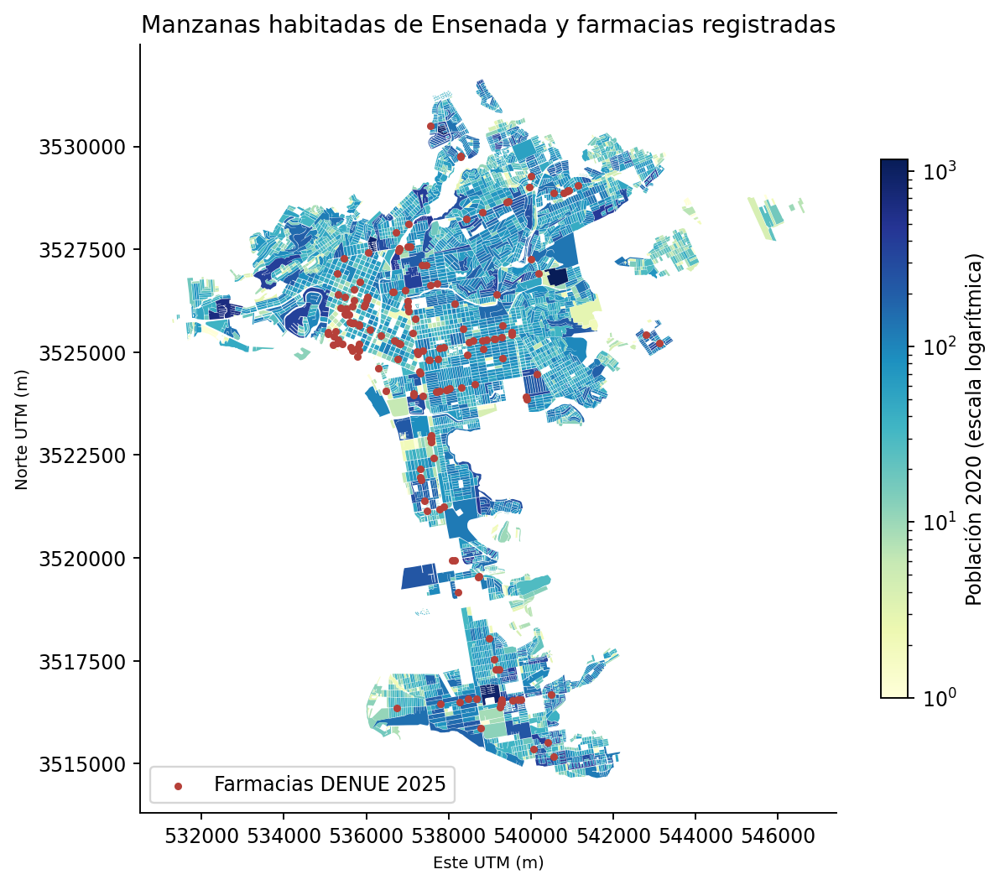

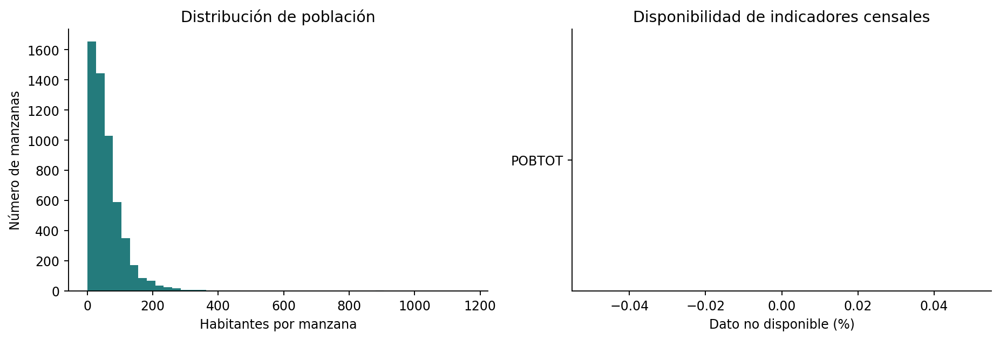

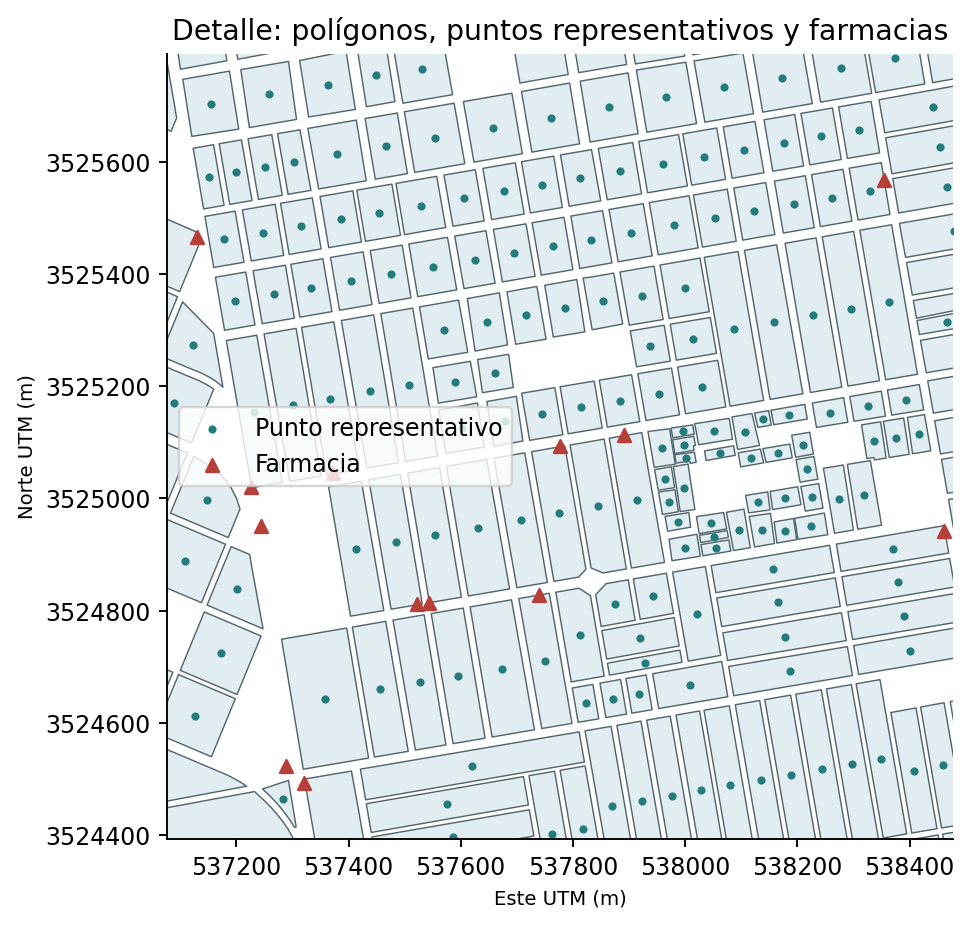

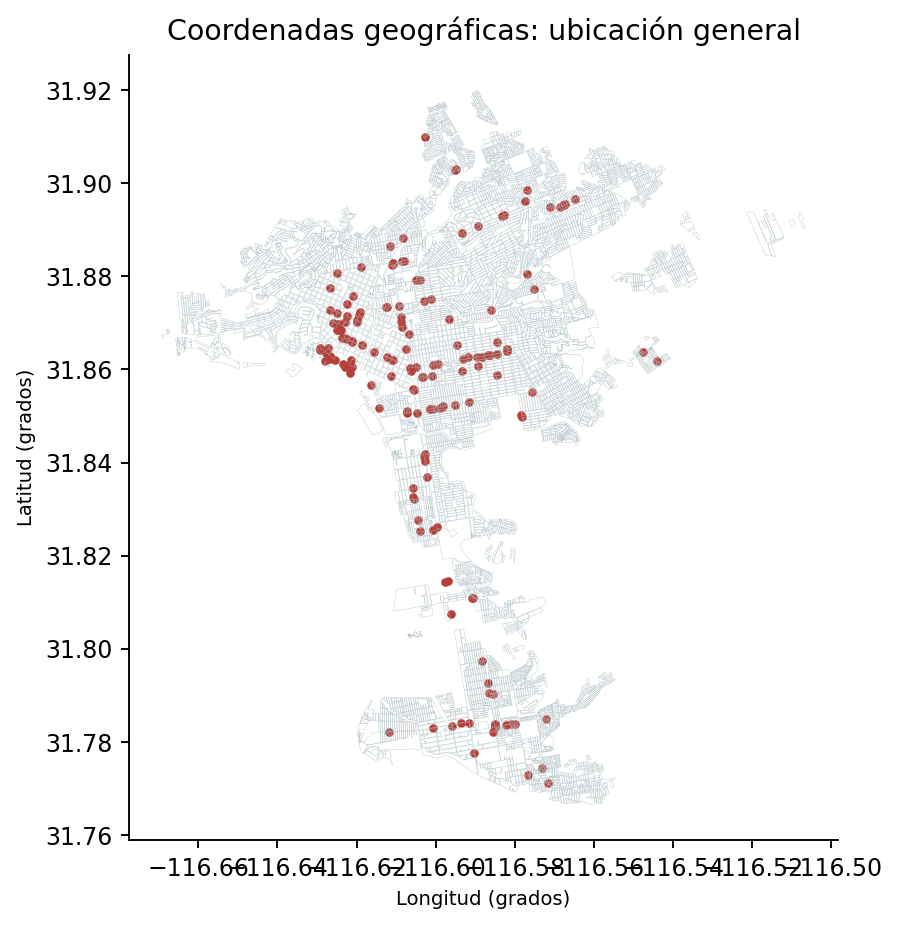

In [56]:
def guardar_figura(fig, nombre):
    fig.savefig(FIGURAS/nombre,dpi=170,bbox_inches='tight')
    plt.close(fig)
    display(Image(filename=str(FIGURAS/nombre)))

farmacias_locales_m = farmacias_m.loc[farmacias_m.clave_localidad.eq(LOCALIDAD)]
fig, ax = plt.subplots(figsize=(8,7))
manzanas_m.plot(ax=ax,column='POBTOT',cmap='YlGnBu',norm=LogNorm(vmin=1,vmax=manzanas_m.POBTOT.max()),
                linewidth=0,legend=True,legend_kwds={'label':'Población 2020 (escala logarítmica)','shrink':.7})
farmacias_locales_m.plot(ax=ax,color='#b64039',markersize=8,label='Farmacias DENUE 2025')
ax.set(title='Manzanas habitadas de Ensenada y farmacias registradas',xlabel='Este UTM (m)',ylabel='Norte UTM (m)')
ax.ticklabel_format(style='plain',useOffset=False);ax.legend(loc='lower left')
guardar_figura(fig,'01_poblacion_farmacias.png')

fig, ejes = plt.subplots(1,2,figsize=(11,3.8))
ejes[0].hist(manzanas_m.POBTOT,bins=45,color='#247b7c')
ejes[0].set(xlabel='Habitantes por manzana',ylabel='Número de manzanas',title='Distribución de población')
calidad_censo.set_index('variable').porcentaje_no_disponible.plot.barh(ax=ejes[1],color='#52646c')
ejes[1].set(xlabel='Dato no disponible (%)',ylabel='',title='Disponibilidad de indicadores censales')
fig.tight_layout();guardar_figura(fig,'02_poblacion_faltantes.png')

centro_xy = np.array([farmacias_locales_m.x_m.median(),farmacias_locales_m.y_m.median()])
indice_centro = np.argmin(np.linalg.norm(farmacias_locales_m[['x_m','y_m']].to_numpy()-centro_xy,axis=1))
centro = farmacias_locales_m.iloc[indice_centro].geometry
radio = 700
vista = manzanas_m.cx[centro.x-radio:centro.x+radio,centro.y-radio:centro.y+radio]
fig, ax = plt.subplots(figsize=(8,6))
vista.plot(ax=ax,facecolor='#e1edf0',edgecolor='#52646c',linewidth=.6)
origenes.loc[origenes.clave_manzana.isin(vista.clave_manzana)].plot(ax=ax,color='#247b7c',markersize=6,label='Punto representativo')
farmacias_m.cx[centro.x-radio:centro.x+radio,centro.y-radio:centro.y+radio].plot(ax=ax,color='#b64039',markersize=30,marker='^',label='Farmacia')
ax.set(xlim=(centro.x-radio,centro.x+radio),ylim=(centro.y-radio,centro.y+radio),
       title='Detalle: polígonos, puntos representativos y farmacias',xlabel='Este UTM (m)',ylabel='Norte UTM (m)')
ax.ticklabel_format(style='plain',useOffset=False);ax.legend()
guardar_figura(fig,'03_detalle_manzanas.png')

fig, ax = plt.subplots(figsize=(7,6))
manzanas_habitadas.to_crs('EPSG:4326').boundary.plot(ax=ax,color='#aebfc4',linewidth=.15)
farmacias.loc[farmacias.clave_localidad.eq(LOCALIDAD)].plot(ax=ax,color='#b64039',markersize=7)
ax.set(title='Coordenadas geográficas: ubicación general',xlabel='Longitud (grados)',ylabel='Latitud (grados)')
guardar_figura(fig,'04_coordenadas_geograficas.png')

## 9. Control espacial de establecimientos
Las claves de DENUE pertenecen a otra fecha. Comprobamos si las coordenadas de las farmacias locales quedan dentro del polígono censal identificado por su clave. Las diferencias se reportan para revisión, no se mueven puntos ni se eliminan farmacias de forma automática. Una clave coincidente no demuestra precisión de la coordenada.

In [57]:
control_farmacias = farmacias_m.loc[farmacias_m.clave_localidad.eq(LOCALIDAD),
    ['id','nom_estab','clave_manzana_denue','geometry']].copy()
control_farmacias = control_farmacias.merge(
    manzanas_geo[['clave_manzana','geometry']].to_crs(CRS_METRICO).rename(columns={'geometry':'poligono_segun_clave'}),
    left_on='clave_manzana_denue',right_on='clave_manzana',how='left',validate='many_to_one')
control_farmacias['tiene_poligono_segun_clave'] = control_farmacias.poligono_segun_clave.notna()
control_farmacias['dentro_poligono_segun_clave'] = [
    punto.covered_by(poligono) if pd.notna(poligono) else False
    for punto,poligono in zip(control_farmacias.geometry,control_farmacias.poligono_segun_clave)]
display(control_farmacias[['tiene_poligono_segun_clave','dentro_poligono_segun_clave']].value_counts().rename('farmacias').reset_index())
control_farmacias['distancia_al_poligono_m'] = [
    punto.distance(poligono) if pd.notna(poligono) else np.nan
    for punto,poligono in zip(control_farmacias.geometry,control_farmacias.poligono_segun_clave)]
display(control_farmacias.distancia_al_poligono_m.describe().to_frame('distancia_al_poligono_m'))
control_farmacias.drop(columns=['geometry','poligono_segun_clave']).to_csv(RESULTADOS/'control_espacial_farmacias.csv',index=False)

,tiene_poligono_segun_clave,dentro_poligono_segun_clave,farmacias
0,True,False,91
1,True,True,74


,distancia_al_poligono_m
count,165.000000
mean,0.424959
std,0.545831
min,0.000000
25%,0.000000
50%,0.045804
75%,0.725171
max,4.141034


## 10. Proximidad, círculos de radio fijo y centros ficticios
Ya que las geometrías comparten CRS métrico, se calcula la distancia euclidiana al establecimiento más cercano. No se exige que esté dentro de Ensenada. Este paso verifica la utilidad de la base, la propuesta de múltiples centros se ejecuta en las subsecciones siguientes.

Un árbol espacial permite buscar el destino más cercano sin construir una matriz completa. Si existen empates de distancia, el ID asignado es una elección entre destinos equivalentes, la distancia no cambia. En la tabla final se conserva una sola fila por manzana.

In [58]:
xy_origen = origenes[['x_m','y_m']].to_numpy()
xy_farmacias = farmacias_m[['x_m','y_m']].to_numpy()
arbol = cKDTree(xy_farmacias)
distancias, indices = arbol.query(xy_origen,k=1)
cercanas = farmacias_m.iloc[indices]
origenes['distancia_m'] = distancias
origenes['farmacia_id'] = cercanas.id.to_numpy()
origenes['farmacia_nombre'] = cercanas.nom_estab.to_numpy()
origenes['destino_fuera_localidad'] = cercanas.clave_localidad.ne(LOCALIDAD).to_numpy()
assert np.isfinite(distancias).all() and (distancias>=0).all()
assert len(origenes)==origenes.clave_manzana.nunique()
manzanas_m = manzanas_m.merge(origenes[['clave_manzana','distancia_m','farmacia_id']],on='clave_manzana',validate='one_to_one')
resumen_dist = dict(media_m=float(distancias.mean()), mediana_m=float(np.median(distancias)),
    p90_m=float(np.quantile(distancias,.9)),maximo_m=float(distancias.max()),
    media_ponderada_poblacion_m=float(np.average(distancias,weights=origenes.POBTOT)),
    manzanas_con_destino_fuera_localidad=int(origenes.destino_fuera_localidad.sum()))
escenarios = pd.DataFrame([dict(umbral_m=r,manzanas=int((distancias>r).sum()),
    poblacion_en_manzanas=int(origenes.loc[distancias>r,'POBTOT'].sum()),
    porcentaje_poblacion=100*origenes.loc[distancias>r,'POBTOT'].sum()/poblacion_retenida)
    for r in [500,1000]])
display(pd.DataFrame([resumen_dist]).T.rename(columns={0:'valor'}))
display(escenarios)
display(origenes.sort_values('distancia_m',ascending=False)[
    ['clave_manzana','POBTOT','distancia_m','farmacia_id','farmacia_nombre']].head(12))
escenarios.to_csv(RESULTADOS/'escenarios_distancia.csv',index=False)

,valor
media_m,651.923569
mediana_m,481.099133
p90_m,1368.430794
maximo_m,4814.799378
media_ponderada_poblacion_m,579.656153
manzanas_con_destino_fuera_localidad,5.000000


,umbral_m,manzanas,poblacion_en_manzanas,porcentaje_poblacion
0,500,2657,141121,42.691235
1,1000,1043,51144,15.471833


,clave_manzana,POBTOT,distancia_m,farmacia_id,farmacia_nombre
5592,0200100010191022,7,4814.799378,10313666,FARMACIA PROSALUD
5540,0200100010191019,10,4607.906026,10313666,FARMACIA PROSALUD
5535,0200100010191013,2,4421.452528,10313666,FARMACIA PROSALUD
5533,0200100010191010,1,4396.810070,10313666,FARMACIA PROSALUD
5507,0200100010191002,17,4233.940484,10313666,FARMACIA PROSALUD
5582,0200100010191001,6,4156.356993,10313666,FARMACIA PROSALUD
5529,0200100010191006,4,4075.029594,10313666,FARMACIA PROSALUD
5558,0200100010191003,25,4021.701485,10313666,FARMACIA PROSALUD
5584,0200100010191012,4,3894.705765,10313666,FARMACIA PROSALUD
5530,0200100010191007,22,3801.301865,10313666,FARMACIA PROSALUD


500 m y 1 km son escenarios exploratorios, no umbrales oficiales de acceso. La población se atribuye a la distancia de un punto representativo, no son distancias individuales. La media ponderada responde a la distribución de habitantes, la mediana sin ponderar responde a la distribución de manzanas. No se mide recorrido por calles, horario, existencias, capacidad ni asequibilidad.

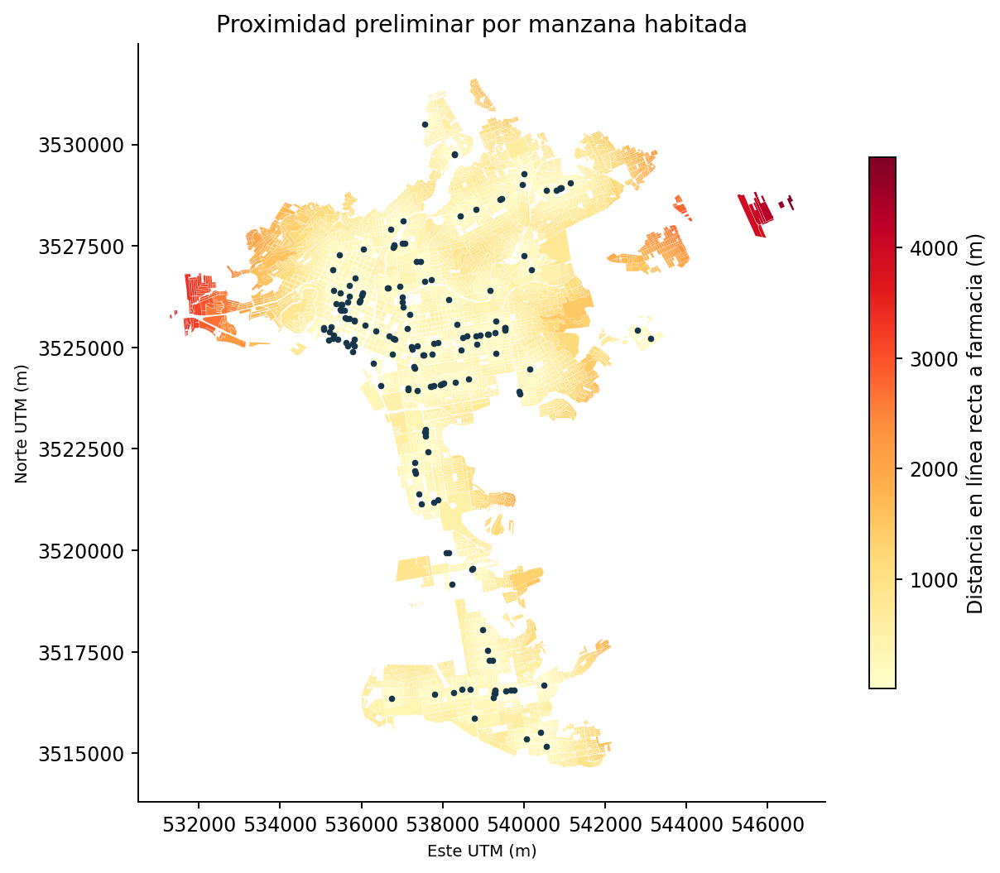

In [59]:
fig, ax = plt.subplots(figsize=(8,7))
manzanas_m.plot(ax=ax,column='distancia_m',cmap='YlOrRd',linewidth=0,legend=True,
    legend_kwds={'label':'Distancia en línea recta a farmacia (m)','shrink':.7})
farmacias_locales_m.plot(ax=ax,color='#17354a',markersize=5)
ax.set(title='Proximidad preliminar por manzana habitada',xlabel='Este UTM (m)',ylabel='Norte UTM (m)')
ax.ticklabel_format(style='plain',useOffset=False)
guardar_figura(fig,'05_proximidad_preliminar.png')

## 11. Establecimientos de contexto: solo puntos por categoría
Se conservan hospitales, supermercados y centros educativos únicamente como capas informativas de puntos en el HTML. No se comparan sus distancias, población cubierta ni ubicación óptima. Las clases del SCIAN solo delimitan qué registros dibujar.

Todo el estudio cuantitativo y el modelado corresponden a farmacias. Se usa población total publicada y geometrías utilizables, los indicadores sociodemográficos incompletos no se incorporan a análisis ni modelos. Las extensiones sobre edad, familias, rentas y rutas se describen al final sin producir resultados con datos que faltan.

In [70]:
CRITERIOS = {'Farmacias': ['464111','464112'], 'Escuelas': '611',
             'Supermercados': ['462111'], 'Hospitales': '622'}
COLORES = {'Farmacias':'#075985','Escuelas':'#7c3aed',
           'Supermercados':'#20845a','Hospitales':'#dc6b18'}
servicios = {}
for nombre, criterio in CRITERIOS.items():
    mascara = (denue_bc.codigo_act.str.startswith(criterio) if isinstance(criterio,str)
               else denue_bc.codigo_act.isin(criterio))
    tabla = denue_bc.loc[mascara & denue_bc.clave_localidad.eq(LOCALIDAD)].copy()
    for col in ['latitud','longitud']:
        tabla[col] = pd.to_numeric(tabla[col],errors='coerce')
    validas = tabla.latitud.between(-90,90) & tabla.longitud.between(-180,180)
    servicios[nombre] = gpd.GeoDataFrame(tabla.loc[validas], geometry=gpd.points_from_xy(
        tabla.loc[validas,'longitud'],tabla.loc[validas,'latitud']),crs='EPSG:4326').to_crs(CRS_METRICO)
print('Capas de puntos preparadas: farmacias, hospitales, supermercados y centros educativos.')
print('Análisis y localización de nuevas ubicaciones: de farmacias.')

Capas de puntos preparadas: farmacias, hospitales, supermercados y centros educativos.
Análisis y localización de nuevas ubicaciones: de farmacias.


## 12. Fondo cartográfico permanente y EDA de población desatendida
El Marco 2020 incluye costa, manzanas y ejes de vialidad. Se usan para un mapa de fondo vectorial que queda siempre visible, incluso sin conexión. Apagar las capas temáticas no lo elimina.

Los ejes tienen algunos atributos, como sentido, pero no hemos validado conectividad, cruces, barreras ni reglas peatonales. Dibujar calles no equivale a calcular una ruta transitable. Para evitar confundir población con superficie vacía, las concentraciones sin cobertura se resumen en celdas de 500 x 500 m, sumando población de manzanas cuyo punto está fuera del radio.

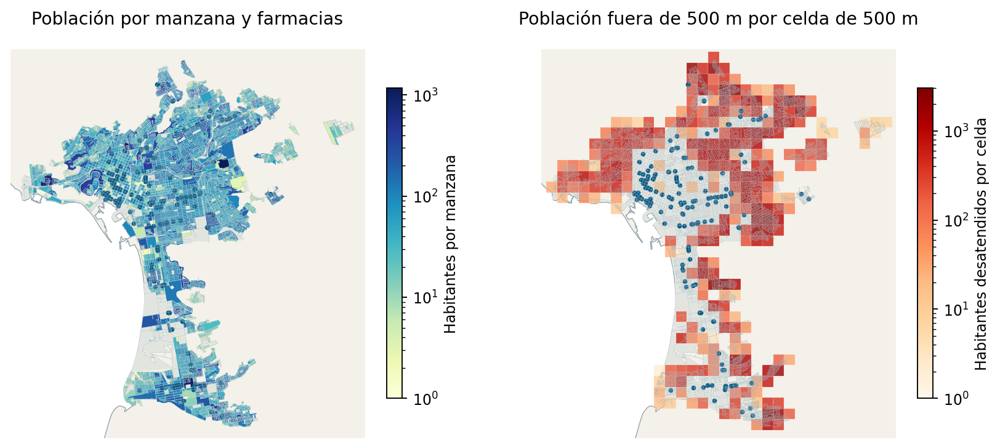

Manzanas fuera de 500 m: 2657
Población asociada fuera de 500 m: 141121
Ejes viales de fondo: 15715


,POBTOT,area_ha,densidad_ha,distancia_m
count,5521.00,5521.00,5521.00,5521.00
mean,59.87,0.91,156.05,651.92
std,60.32,1.94,273.60,574.10
min,1.00,0.01,0.10,15.47
25%,22.00,0.34,43.74,257.14
50%,45.00,0.56,82.88,481.10
75%,79.00,0.98,152.59,858.84
max,1165.00,56.80,3804.25,4814.80


In [61]:
from shapely.geometry import box
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
rutas = {p.stem.lower():p for p in capas}
vias = gpd.read_file(rutas['02e'],engine='pyogrio')
vias = vias.loc[vias.CVEGEO.eq(LOCALIDAD)].to_crs(CRS_METRICO)
xmin,ymin,xmax,ymax = manzanas_m.total_bounds
extension = box(xmin-1800,ymin-1800,xmax+1800,ymax+1800)
tierra = gpd.read_file(rutas['02ent'],engine='pyogrio').to_crs(CRS_METRICO)
tierra.geometry = tierra.geometry.intersection(extension)
tierra = tierra.loc[~tierra.geometry.is_empty].copy()
base_manzanas = manzanas_geo.to_crs(CRS_METRICO)

def fondo(ax):
    ax.set_facecolor('#dcecf1')
    tierra.plot(ax=ax,color='#f3f1e9',edgecolor='#94a8b1',linewidth=.6)
    base_manzanas.plot(ax=ax,color='#e2e5df',edgecolor='white',linewidth=.12)
    vias.plot(ax=ax,color='#a5b6bd',linewidth=.22)
    ax.set_aspect('equal'); ax.set_xlim(xmin-500,xmax+500); ax.set_ylim(ymin-500,ymax+500)
    ax.set_axis_off()

manzanas_m['area_ha'] = manzanas_m.area/10000
assert manzanas_m.area_ha.gt(0).all()
manzanas_m['densidad_ha'] = manzanas_m.POBTOT/manzanas_m.area_ha
manzanas_m['sin_cobertura'] = manzanas_m.distancia_m.gt(RADIO_M)
xy = origenes[['x_m','y_m']].to_numpy()
poblacion = manzanas_m.POBTOT.to_numpy(dtype=np.int64)
d_actual = manzanas_m.distancia_m.to_numpy()
sin_cobertura = d_actual>RADIO_M
sin = origenes.loc[sin_cobertura].copy()
sin['gx'] = np.floor(sin.x_m/500).astype(int)
sin['gy'] = np.floor(sin.y_m/500).astype(int)
rejilla = sin.groupby(['gx','gy'],as_index=False).agg(poblacion=('POBTOT','sum'),manzanas=('clave_manzana','size'))
rejilla = gpd.GeoDataFrame(rejilla,geometry=[box(x*500,y*500,(x+1)*500,(y+1)*500)
    for x,y in zip(rejilla.gx,rejilla.gy)],crs=CRS_METRICO)
fig,ejes = plt.subplots(1,2,figsize=(12,7))
for ax in ejes: fondo(ax)
manzanas_m.plot(ax=ejes[0],column='POBTOT',cmap='YlGnBu',linewidth=0,
                norm=LogNorm(vmin=1,vmax=manzanas_m.POBTOT.max()))
rejilla.plot(ax=ejes[1],column='poblacion',cmap='OrRd',alpha=.8,linewidth=.1,
             edgecolor='#fdf8f2',norm=LogNorm(vmin=1,vmax=rejilla.poblacion.max()))
for ax in ejes: servicios['Farmacias'].plot(ax=ax,color='#075985',markersize=5)
ejes[0].set_title('Población por manzana y farmacias')
ejes[1].set_title('Población fuera de 500 m por celda de 500 m')
fig.colorbar(ScalarMappable(norm=LogNorm(vmin=1,vmax=manzanas_m.POBTOT.max()),cmap='YlGnBu'),ax=ejes[0],shrink=.55,label='Habitantes por manzana')
fig.colorbar(ScalarMappable(norm=LogNorm(vmin=1,vmax=rejilla.poblacion.max()),cmap='OrRd'),ax=ejes[1],shrink=.55,label='Habitantes desatendidos por celda')
guardar_figura(fig,'06_concentraciones.png')
print('Manzanas fuera de 500 m:',int(sin_cobertura.sum()))
print('Población asociada fuera de 500 m:',int(poblacion[sin_cobertura].sum()))
print('Ejes viales de fondo:',len(vias))
display(manzanas_m[['POBTOT','area_ha','densidad_ha','distancia_m']].describe().round(2))

## 13. Formulación y candidatos: pocas aperturas, beneficio adicional
Se fija radio = 500 m y presupuesto principal=5 nuevas ubicaciones antes de comparar. Se exploran 1-10 como escenarios, sin buscar cubrir todo el territorio. Los candidatos son los puntos representativos de manzanas habitadas actualmente fuera del radio. No son predios comerciales disponibles y deberán verificarse en campo.

Para cada candidata $j$ se conoce el conjunto $N_j$ de manzanas actualmente desatendidas a 500 m. Con población $p_i$, se resuelve el problema de cobertura máxima discreta:

$$\max\sum_{i\in U}p_i z_i,\qquad z_i\leq\sum_{j:i\in N_j}x_j,\quad\sum_jx_j\leq5,\quad x_j\in\{0,1\},\quad0\leq z_i\leq1.$$

$U$ contiene las manzanas inicialmente fuera de cobertura. Cada habitante se cuenta una sola vez aunque los círculos se solapen. Maximizar cobertura con presupuesto no implica predecir la apertura de un negocio. La optimalidad, si se certifica, solo vale para estos candidatos, radio y población.

Los modelos comparados: aleatorio uniforme (línea base), K-means ponderado por población ajustado al candidato permitido más cercano, voraz por ganancia marginal y MCLP con programación entera. K-means minimiza distancias cuadráticas, mientras la cobertura se evalúa al mismo radio para todos.

In [62]:
from src.ubicacion import (matriz_cobertura,cubierta_por,seleccion_voraz,
    comparar_completo,evaluar_bloques)
#Orden estable para que los empates y las salidas puedan reproducirse.
candidatos = origenes.loc[sin_cobertura,['clave_manzana','geometry']].sort_values('clave_manzana').reset_index(drop=True)
xy_candidatos = np.c_[candidatos.geometry.x,candidatos.geometry.y]
indices_u = np.flatnonzero(sin_cobertura)
xy_u = xy[indices_u]
pesos_u = poblacion[indices_u]
a = matriz_cobertura(xy_candidatos,xy_u,RADIO_M)
assert a.shape==(len(candidatos),len(indices_u))
assert np.all(np.asarray(a.sum(axis=0)).ravel()>0)
print('Candidatos:',len(candidatos),'Manzanas inicialmente desatendidas:',len(indices_u))
print('Presupuesto principal:',K_PRINCIPAL,'Radio común:',RADIO_M,'m')
display(candidatos.head())

Candidatos: 2657 Manzanas inicialmente desatendidas: 2657
Presupuesto principal: 5 Radio común: 500 m


,clave_manzana,geometry
0,0200100010026001,POINT (537168.042 3528986.509)
1,0200100010026002,POINT (537335.785 3529013.763)
2,0200100010026003,POINT (537560.311 3529030.975)
3,0200100010030004,POINT (539227.562 3519689.317)
4,0200100010030005,POINT (539240.692 3519676.972)


## 14. Comparación justa y variabilidad algorítmica
Se ejecutan 30 semillas para aleatorio y K-means, el voraz es determinista. El solucionador MCLP recibe un límite de 30 s y publica su estado, cota y brecha. Si agota el tiempo no se afirma optimalidad. Esta evaluación sobre el censo observado mide el objetivo de planificación, no es desempeño predictivo fuera de muestra.

,metodo,repeticiones,media,desviacion,minimo,maximo
0,Aleatorio,30,12493.8,2720.9,6263,19447
1,K-means ponderado,30,11952.7,376.2,10570,12326
2,MCLP,1,31188.0,0.0,31188,31188
3,Voraz,1,31188.0,0.0,31188,31188


,estado,mensaje,segundos,brecha_relativa,cota_superior_personas
0,0,Optimization terminated successfully. (HiGHS S...,0.795614,0.0,31188.0


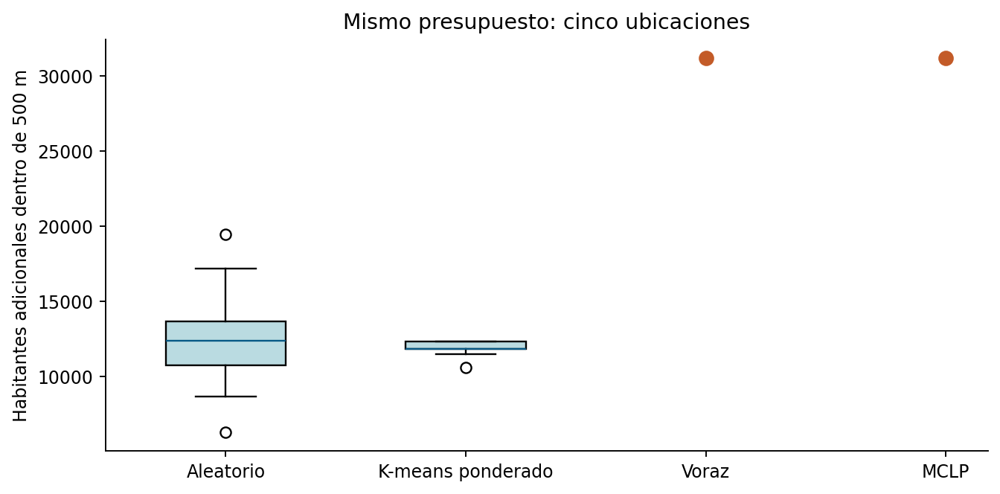

In [63]:
from threadpoolctl import threadpool_limits
with threadpool_limits(limits=1):
    comparaciones,soluciones,ficha_mclp = comparar_completo(
        a,xy_u,xy_candidatos,pesos_u,k=K_PRINCIPAL,repeticiones=30,semilla=SEMILLA)
resumen_modelos = comparaciones.groupby('metodo').poblacion_adicional.agg(
    repeticiones='size',media='mean',desviacion='std',minimo='min',maximo='max').fillna(0).reset_index()
display(resumen_modelos.round(1))
display(pd.DataFrame([ficha_mclp]))
comparaciones.to_csv(RESULTADOS/'comparacion_modelos_30_semillas.csv',index=False)
resumen_modelos.to_csv(RESULTADOS/'resumen_modelos.csv',index=False)
(RESULTADOS/'certificado_mclp.json').write_text(json.dumps(ficha_mclp,ensure_ascii=False,indent=2))
fig,ax=plt.subplots(figsize=(8,4))
orden=['Aleatorio','K-means ponderado','Voraz','MCLP']
for i,nombre in enumerate(orden):
    vals=comparaciones.loc[comparaciones.metodo.eq(nombre),'poblacion_adicional']
    if len(vals)>1: ax.boxplot([vals],positions=[i],widths=.5,patch_artist=True,
                              boxprops={'facecolor':'#badbe1'},medianprops={'color':'#075985'})
    elif len(vals): ax.scatter(i,vals.iloc[0],color='#c35b28',s=60,zorder=5)
ax.set(xticks=range(4),xticklabels=orden,ylabel='Habitantes adicionales dentro de 500 m',
       title='Mismo presupuesto: cinco ubicaciones')
fig.tight_layout(); guardar_figura(fig,'07_comparacion_modelos.png')

## 15. Partición espacial sin usar población de evaluación
Como prueba adicional de transferencia, se crean bloques de 1 km a partir de coordenadas y cinco particiones disjuntas. En cada fold se oculta la población de las manzanas del bloque evaluado: ni K-means ni el voraz reciben esos pesos. La lista de sitios candidatos y las geometrías son información pública fija, conocida antes de la partición. No hay escalado, imputación ni selección de hiperparámetros con los resultados de prueba.

Se evalúa el porcentaje de población inicialmente desatendida del bloque que recibiría cobertura. La media y desviación entre folds expresan heterogeneidad territorial, no un intervalo de confianza sobre personas. Esta prueba es exigente: un bloque sin demanda visible para ajustar puede recibir pocas propuestas. No demuestra capacidad de pronosticar demanda futura. MCLP se usa como referencia del problema censal completo, sin atribuirle una puntuación fuera de muestra.

,fold,metodo,poblacion_prueba,poblacion_adicional,porcentaje_brecha_cerrada
0,1,Aleatorio,25472,4522,17.75
1,1,K-means ponderado,25472,977,3.84
2,1,Voraz,25472,23,0.09
3,2,Aleatorio,31521,3174,10.07
4,2,K-means ponderado,31521,1504,4.77
5,2,Voraz,31521,0,0.00
6,3,Aleatorio,27401,4303,15.70
7,3,K-means ponderado,27401,963,3.51
8,3,Voraz,27401,1429,5.22
9,4,Aleatorio,29572,911,3.08


,metodo,media,desviacion
0,Aleatorio,10.27,6.48
1,K-means ponderado,5.01,2.22
2,Voraz,1.50,2.17


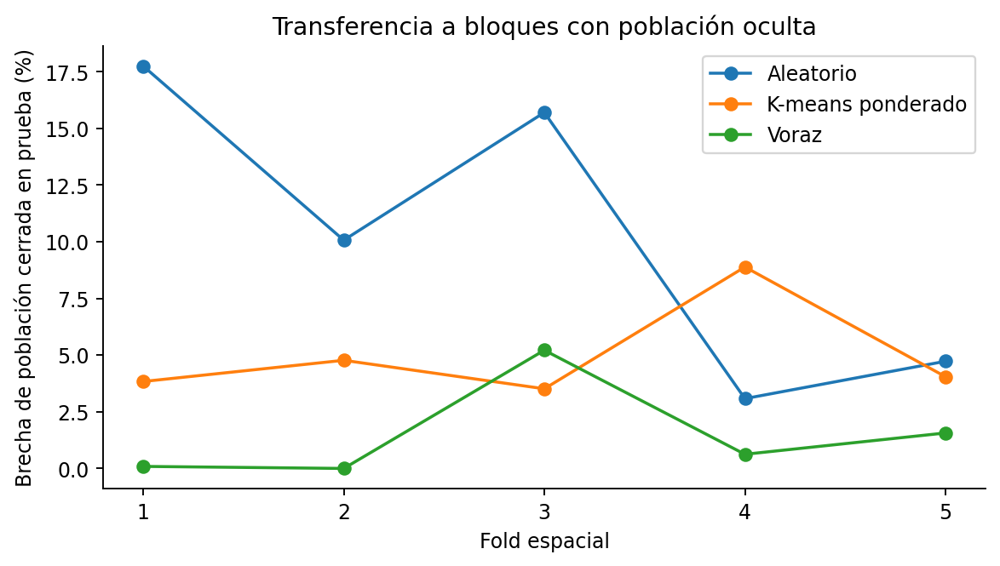

In [64]:
grupos = np.array([f'{int(x//1000)}_{int(y//1000)}' for x,y in xy_u])
with threadpool_limits(limits=1):
    validacion,particiones = evaluar_bloques(a,xy_u,xy_candidatos,pesos_u,grupos,
                                            k=K_PRINCIPAL,semilla=SEMILLA)
resumen_cv = validacion.groupby('metodo').porcentaje_brecha_cerrada.agg(media='mean',desviacion='std').reset_index()
display(validacion.round(2)); display(resumen_cv.round(2))
validacion.to_csv(RESULTADOS/'evaluacion_espacial_5_folds.csv',index=False)
particiones['clave_manzana'] = origenes.iloc[indices_u[particiones.indice.to_numpy()]].clave_manzana.to_numpy()
particiones.to_csv(RESULTADOS/'particiones_espaciales.csv',index=False)
resumen_cv.to_csv(RESULTADOS/'resumen_validacion_espacial.csv',index=False)
fig,ax=plt.subplots(figsize=(7,4))
for nombre,g in validacion.groupby('metodo'):
    ax.plot(g.fold,g.porcentaje_brecha_cerrada,'o-',label=nombre)
ax.set(xlabel='Fold espacial',ylabel='Brecha de población cerrada en prueba (%)',xticks=range(1,6),
       title='Transferencia a bloques con población oculta')
ax.legend();fig.tight_layout();guardar_figura(fig,'08_validacion_espacial.png')

## 16. Propuestas priorizadas y rendimientos decrecientes
El visor presenta la secuencia voraz porque permite añadir una ubicación a la vez, ver su ganancia marginal y conservar las anteriores. No se la llama óptimo global. MCLP proporciona una referencia independiente para cinco sitios.

La secuencia se detiene a más tardar en diez aperturas o si la siguiente aporta menos de 1000 habitantes adicionales. Ese mínimo es una regla de escenario, no una norma clínica ni una estimación de rentabilidad. Los resultados principales se informan para cinco. Se permite solapamiento cuando aporta cobertura nueva, sin contar dos veces a la población.

,clave_manzana,orden,id_propuesta,poblacion_marginal,longitud,latitud,asentamiento_referencia_denue,distancia_a_referencia_m
0,0200100018464005,1,P01,7131,-116.56336,31.85276,MORELOS 1,31.11274
1,0200100019871016,2,P02,6659,-116.58324,31.90567,VILLAS DEL SOL,73.46103
2,020010001973A020,3,P03,6271,-116.56168,31.77116,VILLAS VII,22.97177
3,0200100010115021,4,P04,5585,-116.55012,31.90036,SALVADOR ROSAS MAGALLON,61.57339
4,0200100015987028,5,P05,5542,-116.58585,31.82469,VILLA COLONIAL,38.72135
5,0200100012075013,6,P06,4560,-116.59746,31.91293,LOS ENCINOS,67.84882
6,0200100018746027,7,P07,4431,-116.57689,31.79244,SAN FERNANDO,91.24324
7,020010001845A028,8,P08,4240,-116.56895,31.84785,VILLA BONITA,83.34592
8,0200100016010032,9,P09,4216,-116.58964,31.88114,LOMITAS,43.69811
9,0200100018445041,10,P10,4103,-116.57110,31.88748,POPULAR 1989,31.90386


,k,poblacion_cubierta,poblacion_adicional,porcentaje_cubierto,mediana_distancia_m,media_ponderada_m,poblacion_pendiente
0,0,189441,0,57.31,481.10,579.66,141121
1,1,196572,7131,59.47,465.26,556.26,133990
2,2,203231,13790,61.48,449.66,539.71,127331
3,3,209502,20061,63.38,438.03,526.98,121060
4,4,215087,25646,65.07,429.28,498.84,115475
5,5,220629,31188,66.74,420.87,481.00,109933
6,6,225189,35748,68.12,413.35,471.42,105373
7,7,229620,40179,69.46,405.33,464.60,100942
8,8,233860,44419,70.75,398.47,458.71,96702
9,9,238076,48635,72.02,395.72,452.30,92486


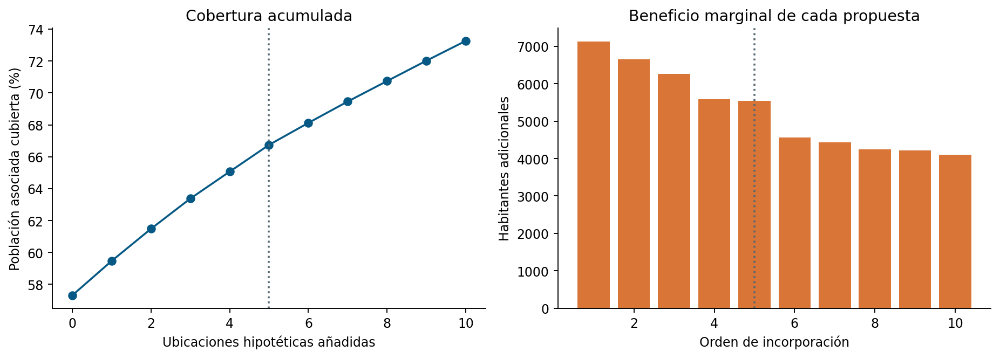

In [65]:
elegidos,ganancias = seleccion_voraz(a,pesos_u,K_MAXIMO,minimo=MINIMO_MARGINAL)
propuestas = candidatos.iloc[elegidos].copy().reset_index(drop=True)
propuestas['orden'] = np.arange(1,len(propuestas)+1)
propuestas['id_propuesta'] = [f'P{i:02d}' for i in propuestas.orden]
propuestas['poblacion_marginal'] = np.array(ganancias,dtype=int)
ll = propuestas.to_crs('EPSG:4326')
propuestas['longitud'] = ll.geometry.x
propuestas['latitud'] = ll.geometry.y
#El asentamiento DENUE más cercano solo se informa como referencia, no como polígono de colonia.
asent = denue_loc.copy()
asent['latitud'] = pd.to_numeric(asent.latitud,errors='coerce')
asent['longitud'] = pd.to_numeric(asent.longitud,errors='coerce')
asent = asent.loc[asent.latitud.between(-90,90)&asent.longitud.between(-180,180)&asent.nomb_asent.notna()]
asent_m = gpd.GeoDataFrame(asent,geometry=gpd.points_from_xy(asent.longitud,asent.latitud),crs='EPSG:4326').to_crs(CRS_METRICO)
d_asent,idx_asent = cKDTree(np.c_[asent_m.geometry.x,asent_m.geometry.y]).query(np.c_[propuestas.geometry.x,propuestas.geometry.y])
propuestas['asentamiento_referencia_denue'] = asent_m.iloc[idx_asent].nomb_asent.to_numpy()
propuestas['distancia_a_referencia_m'] = d_asent
poblacion_cubierta_inicial = int(poblacion[~sin_cobertura].sum())
escenarios=[]
dist_prefix=[d_actual.copy()]
for k in range(len(propuestas)+1):
    if k>0:
        d_nueva=np.linalg.norm(xy-np.array([propuestas.iloc[k-1].geometry.x,propuestas.iloc[k-1].geometry.y]),axis=1)
        dist_prefix.append(np.minimum(dist_prefix[-1],d_nueva))
    d=dist_prefix[k]
    escenarios.append(dict(k=k,poblacion_cubierta=int(poblacion[d<=RADIO_M].sum()),
        poblacion_adicional=int(poblacion[d<=RADIO_M].sum())-poblacion_cubierta_inicial,
        porcentaje_cubierto=100*poblacion[d<=RADIO_M].sum()/poblacion.sum(),
        mediana_distancia_m=np.median(d),media_ponderada_m=np.average(d,weights=poblacion),
        poblacion_pendiente=int(poblacion[d>RADIO_M].sum())))
escenarios=pd.DataFrame(escenarios)
display(propuestas.drop(columns='geometry').round(5));display(escenarios.round(2))
propuestas.drop(columns='geometry').to_csv(RESULTADOS/'propuestas_priorizadas.csv',index=False)
escenarios.to_csv(RESULTADOS/'escenarios_1_a_10.csv',index=False)
fig,ejes=plt.subplots(1,2,figsize=(11,4))
ejes[0].plot(escenarios.k,escenarios.porcentaje_cubierto,'o-',color='#075985')
ejes[0].set(xlabel='Ubicaciones hipotéticas añadidas',ylabel='Población asociada cubierta (%)',title='Cobertura acumulada')
ejes[1].bar(propuestas.orden,propuestas.poblacion_marginal,color='#d97536')
ejes[1].set(xlabel='Orden de incorporación',ylabel='Habitantes adicionales',title='Beneficio marginal de cada propuesta')
for ax in ejes: ax.axvline(K_PRINCIPAL,ls=':',color='#546771')
fig.tight_layout();guardar_figura(fig,'09_escenarios.png')

## 17. Análisis de pendientes y sensibilidad del estudio de farmacias
Se revisan las manzanas que permanecen lejos después de cinco propuestas. Se trabaja con población total publicada, puntos y polígonos válidos. No se calculan perfiles con variables de edad u otros indicadores incompletos.

La sensibilidad a 300, 500 y 1000 m vuelve a construir el conjunto de manzanas desatendidas y la matriz de cobertura en cada escenario. No se comparan radios como si fueran modelos con igual objetivo. También se muestra el efecto de sustituir todos los centroides por puntos interiores.

,clave_manzana,POBTOT,distancia_m,distancia_con_5_m
5510,0200100016025001,637,2585.2,2585.2
2994,0200100018394002,429,805.9,805.9
2887,0200100011043026,429,550.9,550.9
5270,0200100010435025,400,764.8,764.8
5475,0200100017697052,386,1558.5,1558.5
5453,0200100010647001,363,830.2,830.2
4528,0200100019621003,357,863.5,863.5
161,0200100017729022,322,781.3,781.3
4898,0200100010098022,291,1609.8,1609.8
5209,0200100015968023,285,1053.3,906.8


,radio_m,poblacion_inicialmente_fuera,poblacion_adicional_5,porcentaje_cubierto_final
0,300,220116,18852,39.11
1,500,141121,31188,66.74
2,1000,51144,33914,94.79


Manzanas cuya cobertura cambia con otro punto interior: 33


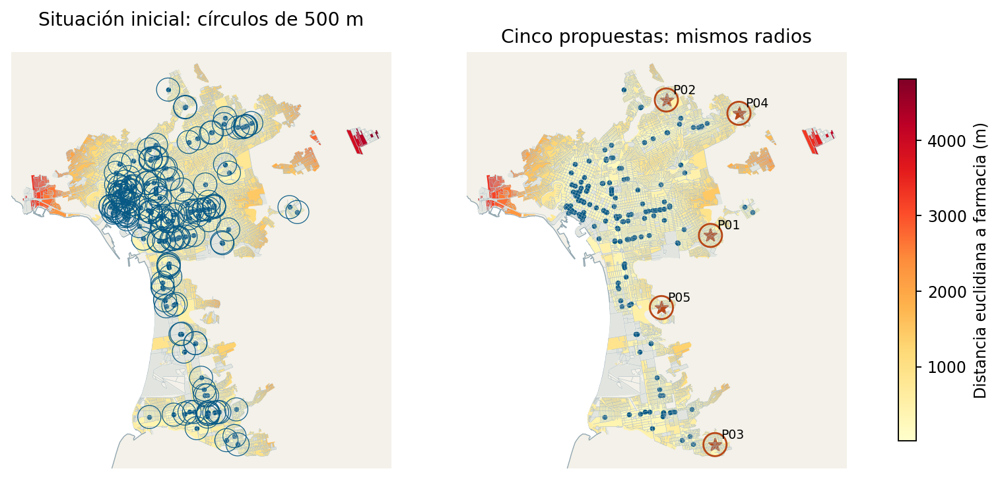

In [66]:
k_efectivo = min(K_PRINCIPAL,len(propuestas))
d_final = dist_prefix[k_efectivo]
pendientes=manzanas_m.loc[d_final>RADIO_M].copy()
pendientes['distancia_con_5_m']=d_final[d_final>RADIO_M]
display(pendientes.sort_values('POBTOT',ascending=False)[
    ['clave_manzana','POBTOT','distancia_m','distancia_con_5_m']].head(10).round(1))
pendientes.drop(columns='geometry').to_csv(RESULTADOS/'manzanas_pendientes_5.csv',index=False)
sensibilidad=[]
for r in [300,500,1000]:
    u=d_actual>r
    xy_r=xy[u];p_r=poblacion[u]
    a_r=matriz_cobertura(xy_r,xy_r,r)
    s_r,_=seleccion_voraz(a_r,p_r,K_PRINCIPAL)
    adicional=int(p_r[cubierta_por(a_r,s_r)].sum())
    sensibilidad.append(dict(radio_m=r,poblacion_inicialmente_fuera=int(p_r.sum()),
        poblacion_adicional_5=adicional,porcentaje_cubierto_final=100*(poblacion[~u].sum()+adicional)/poblacion.sum()))
sensibilidad=pd.DataFrame(sensibilidad)
display(sensibilidad.round(2));sensibilidad.to_csv(RESULTADOS/'sensibilidad_radio.csv',index=False)
puntos_interiores=manzanas_m.geometry.representative_point()
d_interior,_=arbol.query(np.c_[puntos_interiores.x,puntos_interiores.y])
print('Manzanas cuya cobertura cambia con otro punto interior:',int(((d_interior<=RADIO_M)!=(d_actual<=RADIO_M)).sum()))
fig,ejes=plt.subplots(1,2,figsize=(12,7))
for ax in ejes:fondo(ax)
manzanas_m.plot(ax=ejes[0],column='distancia_m',cmap='YlOrRd',linewidth=0)
servicios['Farmacias'].geometry.buffer(RADIO_M).boundary.plot(ax=ejes[0],color='#075985',linewidth=.5)
manzanas_m.assign(distancia_final=d_final).plot(ax=ejes[1],column='distancia_final',cmap='YlOrRd',linewidth=0,
    vmin=manzanas_m.distancia_m.min(),vmax=manzanas_m.distancia_m.max())
servicios['Farmacias'].plot(ax=ejes[0],color='#075985',markersize=5)
servicios['Farmacias'].plot(ax=ejes[1],color='#075985',markersize=5)
propuestas.head(k_efectivo).geometry.buffer(RADIO_M).boundary.plot(ax=ejes[1],color='#b74718',linewidth=1.2)
propuestas.head(k_efectivo).plot(ax=ejes[1],color='#b74718',marker='*',markersize=70)
for _,p in propuestas.head(k_efectivo).iterrows():
    ejes[1].annotate(p.id_propuesta,(p.geometry.x,p.geometry.y),fontsize=8,xytext=(4,4),textcoords='offset points')
ejes[0].set_title('Situación inicial: círculos de 500 m')
ejes[1].set_title('Cinco propuestas: mismos radios')
fig.colorbar(ScalarMappable(norm=Normalize(vmin=manzanas_m.distancia_m.min(),vmax=manzanas_m.distancia_m.max()),cmap='YlOrRd'),ax=list(ejes),shrink=.6,label='Distancia euclidiana a farmacia (m)')
guardar_figura(fig,'10_antes_despues.png')

## 18. Visor interactivo: mapa fijo y controles
Se generan un HTML autocontenido y botones para las cuatro categorías de puntos. El mapa cartográfico permanente incluye costa, calles y manzanas, con información embebida y Leaflet local. No solicita teselas de OpenStreetMap ni otros servicios.

Se pueden activar círculos de farmacias, concentraciones desatendidas y propuestas. El selector de 0–10 propuestas actualiza la cobertura y la distancia simuladas. Se ofrece una vista inicial y una vista de propuestas para ilustrar la exposición.

In [67]:
from src.visor import crear_visor
archivo_html=RESULTADOS/'Mapa_Ensenada_Cobertura_Actual_y_Ficticia.html'
crear_visor(archivo_html,BASE/'assets',tierra,vias,base_manzanas,manzanas_m,
            servicios,propuestas,rejilla,dist_prefix,RADIO_M,K_PRINCIPAL)
print('Visor exportado:',archivo_html.relative_to(BASE))
from IPython.display import HTML
# El archivo original también puede abrirse directamente en el navegador sin conexión.
display(HTML('<p><a href="resultados/'+archivo_html.name+'" target="_blank">Abrir visor interactivo completo</a></p>'))
# Se embebe el HTML para que la salida del notebook conserve la aplicación.
import base64, warnings
src64=base64.b64encode(archivo_html.read_bytes()).decode()
with warnings.catch_warnings():
    warnings.simplefilter('ignore',UserWarning)
    display(HTML('<iframe title="Visor de Ensenada" src="data:text/html;base64,'+src64+'" style="width:100%;height:650px;border:1px solid #ccd6dc"></iframe>'))

Visor exportado: resultados/Mapa_Ensenada_Cobertura_Actual_y_Ficticia.html


## 19. Respuestas, alcance y extensiones concretas
Este estudio permite priorizar sitios geométricos y cuantificar a quiénes beneficia un presupuesto limitado, bajo un escenario euclidiano. No estima demanda clínica, rentabilidad, aperturas futuras ni garantiza que un predio sea utilizable.

| Extensión | Información adicional necesaria | Límite actual |
|---|---|---|
| Priorizar mayores de 60 años | Edad con cobertura suficiente, validación de necesidades y movilidad | La edad no equivale a dependencia de una farmacia; existen datos reservados |
| Familias con baja, media o alta necesidad | Preferencias declaradas, frecuencia de compra, movilidad, presupuesto y umbrales acordados con usuarios | No se pueden inferir estos tres perfiles de una manzana ni asignarlos por edad |
| Elegir colonias para rentar | Polígonos de colonias verificados, anuncios de renta fechados, presupuesto, escuelas y demás servicios | AGEB y manzana no equivalen a colonia; DENUE no contiene rentas |
| Farmacias 24 h y calidad percibida | Horarios verificados por sucursal, reseñas obtenidas de forma autorizada, fecha y correspondencia de establecimientos | Las reseñas no miden calidad clínica y sus usuarios no son una muestra representativa |
| Rutas caminables | Grafo conectado y validado, restricciones, cruces, pendientes, velocidades y acceso al local | Los ejes cartográficos 2020 no han sido preparados ni validados para enrutamiento |

La función de selección residencial podría combinar costos normalizados y pesos declarados por el hogar, por ejemplo $S=w_f d_f+w_e d_e+w_c d_c+w_r R$, restringiendo presupuesto y tiempos máximos. Es una propuesta de investigación futura, no un ranking calculado aquí. Los tres perfiles cambiarían los pesos y restricciones, sin etiquetar clínicamente a personas o colonias.


In [68]:
principal=escenarios.loc[escenarios.k.eq(k_efectivo)].iloc[0]
valor_voraz=int(comparaciones.loc[comparaciones.metodo.eq('Voraz'),'poblacion_adicional'].iloc[0])
valor_mclp=(int(comparaciones.loc[comparaciones.metodo.eq('MCLP'),'poblacion_adicional'].iloc[0])
             if comparaciones.metodo.eq('MCLP').any() else None)
resumen_final=dict(manzanas=len(manzanas_m),poblacion=int(poblacion.sum()),
    poblacion_censal=int(poblacion_origen),poblacion_excluida=int(poblacion_origen-poblacion.sum()),
    farmacias_locales=len(servicios['Farmacias']),radio_m=RADIO_M,k_principal=k_efectivo,
    poblacion_cubierta_inicial=poblacion_cubierta_inicial,
    poblacion_inicialmente_fuera=int(pesos_u.sum()),
    poblacion_adicional_5=int(principal.poblacion_adicional),
    porcentaje_inicial=100*poblacion_cubierta_inicial/poblacion.sum(),
    porcentaje_final_5=float(principal.porcentaje_cubierto),
    poblacion_pendiente_5=int(principal.poblacion_pendiente),
    propuestas_maximas=len(propuestas),minimo_marginal=MINIMO_MARGINAL,
    mclp=valor_mclp,brecha_mclp=ficha_mclp['brecha_relativa'],
    discrepancias_punto=int(((d_interior<=RADIO_M)!=(d_actual<=RADIO_M)).sum()),
    repo_url=REPO_URL)
(RESULTADOS/'resumen_final.json').write_text(json.dumps(resumen_final,ensure_ascii=False,indent=2))
display(Markdown(f"""### Conclusiones de esta ejecución
- Se analizan **{len(manzanas_m):,} manzanas** y **{poblacion.sum():,} habitantes** con geometría utilizable. Quedan fuera **{poblacion_origen-poblacion.sum():,} habitantes** por falta de polígono utilizable.
- Hay **{len(servicios['Farmacias'])} farmacias** registradas en la localidad. La búsqueda de cercanía usa todo BC.
- La cobertura inicial a 500 m es **{resumen_final['porcentaje_inicial']:.1f}%** de la población asociada.
- Cinco propuestas voraces incorporan **{int(principal.poblacion_adicional):,} habitantes adicionales** y elevan esa cobertura a **{principal.porcentaje_cubierto:.1f}%**.
- Permanecen **{int(principal.poblacion_pendiente):,} habitantes** asociados a manzanas fuera del radio. El presupuesto prioriza beneficio; no resuelve toda la cobertura.
- Estado MCLP: **{ficha_mclp['mensaje']}**. La tabla de brecha evita atribuir optimalidad sin evidencia.
- En bloques con población oculta, la selección aleatoria supera al voraz: la solución censal depende de conocer la demanda local. No se presenta como predicción transferible a zonas sin información.
"""))
#Datos derivados livianos, los ZIP estatales se obtienen mediante las URLs declaradas.
manzanas_m.to_file(RESULTADOS/'estudio_utm11.gpkg',layer='manzanas',driver='GPKG')
propuestas.to_file(RESULTADOS/'estudio_utm11.gpkg',layer='propuestas',driver='GPKG')
print('Enlace del repositorio:',REPO_URL or 'PENDIENTE: completar antes de entregar.')

### Conclusiones de esta ejecución
- Se analizan **5,521 manzanas** y **330,562 habitantes** con geometría utilizable. Quedan fuera **90 habitantes** por falta de polígono utilizable.
- Hay **165 farmacias** registradas en la localidad. La búsqueda de cercanía usa todo BC.
- La cobertura inicial a 500 m es **57.3%** de la población asociada.
- Cinco propuestas voraces incorporan **31,188 habitantes adicionales** y elevan esa cobertura a **66.7%**.
- Permanecen **109,933 habitantes** asociados a manzanas fuera del radio. El presupuesto prioriza beneficio; no resuelve toda la cobertura.
- Estado MCLP: **Optimization terminated successfully. (HiGHS Status 7: Optimal)**. La tabla de brecha evita atribuir optimalidad sin evidencia.
- En bloques con población oculta, la selección aleatoria supera al voraz: la solución censal depende de conocer la demanda local. No se presenta como predicción transferible a zonas sin información.


Enlace del repositorio: https://github.com/Marlu-Viut/IDC-2026/tree/main/ICD-26/Proyecto


## 20. Referencias
- INEGI. [Censo de Población y Vivienda 2020](https://www.inegi.org.mx/programas/ccpv/2020/), resultados por AGEB y manzana urbana.
- INEGI. [Marco Geoestadístico, Censo 2020](https://www.inegi.org.mx/temas/mg/), Baja California, capas 02m, 02e y 02ent.
- INEGI. [DENUE](https://www.inegi.org.mx/app/mapa/denue/), edición mayo de 2025, Baja California.
- Church, R. y ReVelle, C. (1974). *The maximal covering location problem*. Papers in Regional Science, 32, 101–118. [DOI](https://doi.org/10.1111/j.1435-5597.1974.tb00902.x).
- SciPy. [Programación entera mixta, estado y brecha de milp](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.milp.html).
- scikit-learn. [KMeans](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html) y [GroupKFold](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GroupKFold.html).
- Leaflet 1.9.4. [Documentación](https://leafletjs.com/reference-1.9.4.html) y licencia BSD-2-Clause incluida en assets.

Fuente cartográfica y estadística: INEGI. Selección, transformaciones, análisis y propuestas: elaboración propia; no constituyen un producto ni recomendación oficial del Instituto.

## Declaración de uso de inteligencia artificial generativa
Se utilizó ChatGPT (OpenAI) para apoyar la delimitación del estudio, la revisión de código Python, la construcción del visor y la redacción inicial de explicaciones y documentos. Las cifras mostradas proceden de la ejecución del código sobre las fuentes declaradas, no de respuestas generadas como si fueran observaciones.